# Assignment 4: Controlling Mountain Car
## Reinforcement Learning — Q-Learning with a Discretized State Space

**Course:** Artificial Intelligence  
**Assignment:** Controlling Mountain Car (`MountainCar-v0`)  
**Team name:** [Enter team name]  
**Team members and registration numbers:**  
1. [Full name — Registration number]  
2. [Full name — Registration number]  
3. [Add or remove rows as needed]

This is the Python programming component. The accompanying PDF contains the theoretical report.

### Notebook contents
1. Install and import dependencies
2. Create the environment
3. Discretize continuous observations
4. Build a Q-table
5. Train using Q-learning
6. Evaluate the learned policy
7. Plot learning progress
8. Save and reload the Q-table

## 1. Aim and objectives

Train an agent to drive an underpowered car up a steep hill. It must learn to move backwards and forwards to build momentum before climbing to the goal.

Objectives:
- Understand the observation, action, reward and episode-ending conditions.
- Convert continuous position and velocity into discrete indexes.
- Implement tabular Q-learning and epsilon-greedy exploration.
- Evaluate the learned policy and report measured results.

## 2. Install and import libraries

Run the installation cell if the packages are not already installed. This notebook uses Gymnasium, the maintained successor to OpenAI Gym.

In [1]:
%pip install -q "gymnasium[classic-control]" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
from pathlib import Path
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Gymnasium version:", gym.__version__)

Gymnasium version: 1.4.0


## 3. Create and understand the environment

`MountainCar-v0` returns two continuous observations: position and velocity. It has three actions: `0` push left, `1` neutral, and `2` push right. The standard task gives -1 per time step, has a goal near position 0.5, and limits an episode to 200 steps.

In [3]:
ENV_NAME = "MountainCar-v0"
MAX_STEPS = 200

env = gym.make(ENV_NAME)
observation, info = env.reset(seed=SEED)
print("Initial observation [position, velocity]:", observation)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
env.close()

Initial observation [position, velocity]: [-0.4452088  0.       ]
Observation space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space: Discrete(3)


## 4. Discretize the continuous state

The supplied `environment.py` specifies 40 position bins and 40 velocity bins. This notebook preserves those settings. There are 39 internal boundaries for each dimension; `np.digitize` maps observations to indexes from 0 to 39.

In [4]:
POSITION_BINS = 40
VELOCITY_BINS = 40
ACTION_COUNT = 3

def make_bins():
    position_bins = np.linspace(-1.2, 0.6, POSITION_BINS - 1)
    velocity_bins = np.linspace(-0.07, 0.07, VELOCITY_BINS - 1)
    return position_bins, velocity_bins

def get_state(observation, bins):
    position, velocity = observation
    p = int(np.digitize(position, bins[0]))
    v = int(np.digitize(velocity, bins[1]))
    # Defensive clipping guarantees valid Q-table indexes.
    p = int(np.clip(p, 0, POSITION_BINS - 1))
    v = int(np.clip(v, 0, VELOCITY_BINS - 1))
    return p, v

bins = make_bins()
print("Example discrete state:", get_state(np.array([-0.5, 0.02]), bins))

Example discrete state: (15, 25)


## 5. Create the Q-table

The table stores one value for each discrete state-action pair. Its dimensions are 40 × 40 × 3 = 4,800 values. It begins with zeros.

In [5]:
def create_q_table():
    return np.zeros((POSITION_BINS, VELOCITY_BINS, ACTION_COUNT), dtype=np.float32)

q_table = create_q_table()
print("Q-table shape:", q_table.shape)
print("Number of Q-values:", q_table.size)

Q-table shape: (40, 40, 3)
Number of Q-values: 4800


## 6. Q-learning and epsilon-greedy action selection

Q-learning is a model-free, off-policy algorithm. Its update rule is:

\[
Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma \max_{a'}Q(s',a') - Q(s,a)]
\]

Epsilon-greedy selection explores by choosing a random action with probability epsilon; otherwise it exploits the current best Q-value. Random tie-breaking avoids always choosing the first action when values are equal.

In [6]:
def choose_action(state, q_values, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(ACTION_COUNT))
    values = q_values[state[0], state[1], :]
    best_actions = np.flatnonzero(values == np.max(values))
    return int(rng.choice(best_actions))

def q_learning_update(q_values, state, action, reward, next_state,
                      terminated, alpha, gamma):
    current = q_values[state[0], state[1], action]
    if terminated:
        target = reward
    else:
        target = reward + gamma * np.max(q_values[next_state[0], next_state[1], :])
    q_values[state[0], state[1], action] = current + alpha * (target - current)

## 7. Train the agent

Gymnasium's `step()` returns five values: next observation, reward, terminated, truncated and info. Both `terminated` and `truncated` end an episode. The update suppresses future-value bootstrapping only for a true terminal state; a time-limit truncation is not treated as reaching the goal.

The hyperparameters below are starting values, not a guarantee of a particular success rate.

In [7]:
EPISODES = 3000
ALPHA = 0.1
GAMMA = 0.99
EPSILON_START = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.9995

rng = np.random.default_rng(SEED)
q_table = create_q_table()
episode_rewards, episode_steps, success_history = [], [], []
epsilon = EPSILON_START
train_env = gym.make(ENV_NAME)

for episode in range(EPISODES):
    observation, info = train_env.reset(seed=SEED + episode)
    state = get_state(observation, bins)
    total_reward = 0.0
    reached_goal = False

    for step in range(MAX_STEPS):
        action = choose_action(state, q_table, epsilon, rng)
        next_obs, reward, terminated, truncated, info = train_env.step(action)
        next_state = get_state(next_obs, bins)
        q_learning_update(q_table, state, action, reward, next_state,
                          terminated, ALPHA, GAMMA)
        state = next_state
        total_reward += reward
        if terminated:
            reached_goal = True
        if terminated or truncated:
            break

    episode_rewards.append(total_reward)
    episode_steps.append(step + 1)
    success_history.append(int(reached_goal))
    epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)

    if (episode + 1) % 1000 == 0:
        print(f"Episode {episode+1}/{EPISODES}; epsilon={epsilon:.3f}; "
              f"last-100 reward={np.mean(episode_rewards[-100:]):.2f}; "
              f"last-100 success={np.mean(success_history[-100:]):.1%}")

train_env.close()
print("Training complete.")

Episode 1000/3000; epsilon=0.606; last-100 reward=-200.00; last-100 success=0.0%


Episode 2000/3000; epsilon=0.368; last-100 reward=-200.00; last-100 success=0.0%


Episode 3000/3000; epsilon=0.223; last-100 reward=-198.09; last-100 success=9.0%
Training complete.


## 8. Evaluate the learned policy

Evaluation sets epsilon to zero: the agent follows its greedy policy without deliberate random exploration. Success means the environment reports `terminated=True`, not merely that the time limit was reached.

In [8]:
def evaluate_policy(q_values, episodes=100, seed=10000):
    eval_env = gym.make(ENV_NAME)
    rewards, steps, successes = [], [], []

    for episode in range(episodes):
        obs, info = eval_env.reset(seed=seed + episode)
        state = get_state(obs, bins)
        total_reward = 0.0
        success = False

        for step in range(MAX_STEPS):
            action = int(np.argmax(q_values[state[0], state[1], :]))
            next_obs, reward, terminated, truncated, info = eval_env.step(action)
            state = get_state(next_obs, bins)
            total_reward += reward
            if terminated:
                success = True
            if terminated or truncated:
                break

        rewards.append(total_reward)
        steps.append(step + 1)
        successes.append(int(success))

    eval_env.close()
    return {
        "mean_reward": float(np.mean(rewards)),
        "mean_steps": float(np.mean(steps)),
        "success_rate": float(np.mean(successes)),
        "rewards": rewards,
        "steps": steps,
        "successes": successes
    }

evaluation = evaluate_policy(q_table, episodes=100)
print(f"Mean reward: {evaluation['mean_reward']:.2f}")
print(f"Mean steps: {evaluation['mean_steps']:.2f}")
print(f"Success rate: {evaluation['success_rate']:.1%}")

Mean reward: -179.52
Mean steps: 179.52
Success rate: 66.0%


## 9. Plot learning progress

A moving average smooths the episode-to-episode variation. Since each step has reward -1, a reward closer to zero generally means the agent completed the episode in fewer steps. Success rate separately measures how often the goal was reached.

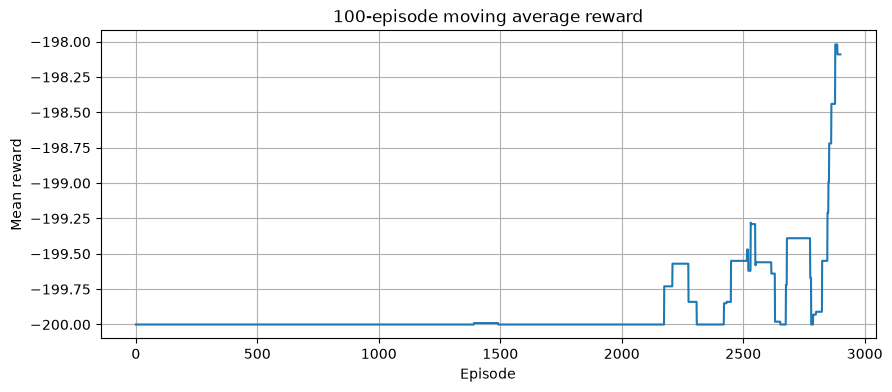

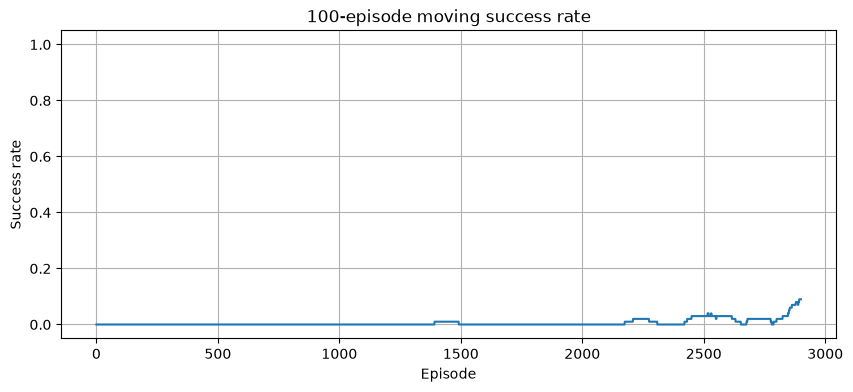

In [9]:
def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)
    return np.convolve(values, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_average(episode_rewards))
plt.title("100-episode moving average reward")
plt.xlabel("Episode")
plt.ylabel("Mean reward")
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(moving_average(success_history))
plt.title("100-episode moving success rate")
plt.xlabel("Episode")
plt.ylabel("Success rate")
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.show()

## 10. Save and reload the Q-table

The supplied `.gitignore` excludes `q_table.npy`. It will therefore normally be omitted from Git commits. If the lecturer requires the trained table as a deliverable, submit it separately or revise the ignore rule with the team's agreement.

In [10]:
q_table_path = Path("q_table.npy")
np.save(q_table_path, q_table)
print("Saved:", q_table_path.resolve())

loaded_q_table = np.load(q_table_path)
print("Reloaded shape:", loaded_q_table.shape)
print("Tables match:", np.allclose(q_table, loaded_q_table))

Saved: /home/gwaiffemark/Desktop/Projects/MountainCar_AI/q_table.npy
Reloaded shape: (40, 40, 3)
Tables match: True


## 11. Optional rendered demonstration

This cell requires a graphical display. Skip it in hosted environments that cannot open a render window; training and numerical evaluation do not depend on it.

In [11]:
# Headless-safe demonstration: collect one final frame instead of opening a window.
render_env = gym.make(ENV_NAME, render_mode="rgb_array")
obs, info = render_env.reset(seed=2026)
state = get_state(obs, bins)
frames = []
for step in range(MAX_STEPS):
    action = int(np.argmax(q_table[state[0], state[1], :]))
    obs, reward, terminated, truncated, info = render_env.step(action)
    state = get_state(obs, bins)
    if step == 0 or terminated or truncated:
        frames.append(render_env.render())
    if terminated or truncated:
        break
render_env.close()
print("Rendered demonstration frames:", len(frames))


Rendered demonstration frames: 2


## 12. Implementation explanation

| Function/component | Responsibility |
|---|---|
| `make_bins()` | Creates position and velocity boundaries. |
| `get_state()` | Maps continuous observations to discrete indexes. |
| `create_q_table()` | Allocates the 4,800 zero-valued entries. |
| `choose_action()` | Implements epsilon-greedy action selection. |
| `q_learning_update()` | Applies the temporal-difference update. |
| Training loop | Interacts with the environment and learns Q-values. |
| `evaluate_policy()` | Measures the greedy policy without exploration. |
| Save/load cells | Persist the Q-table using NumPy. |

### Limitations
- Discretization loses precision; different observations can map to the same bin.
- Hyperparameters and training duration affect the outcome.
- Results vary across runs; repeated-seed evaluation is stronger evidence.
- A tabular Q-table does not scale well to high-dimensional state spaces.
- Rendering may not be available in a remote notebook.

## 13. Submission checklist
- [ ] Replace team name and member placeholders.
- [x] Run all cells from top to bottom in one Python environment.
- [x] Keep the actual evaluation output and plots; do not invent results.
- [x] Submit this single Python notebook as the programming component.
- [x] Submit the accompanying theoretical PDF.
- [ ] Upload the team's notebook and PDF to Muele as instructed.
